# TP1 — Parte I | EPH 2026-T1
Predicción de informalidad con **15 variables originales**, variables familiares y preparación reproducible.

## 0.1. Librerías
Paquetes para limpieza, descripción, visualización y preparación de los datos.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from os.path import join
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.linalg import qr

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.neighbors import KNeighborsClassifier

## 0.2. Rutas
Se respetan las carpetas existentes del repositorio, sin crear otras.

In [2]:
# Ruta principal
main_path = Path("D:/Github/PE1333_Grupo8/TP_01")

# Carpetas principales
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")

# Carpetas secundarias
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")
b_path_text = join(b_path, "B_Text")

## 0.3. Lectura de datos
Se cargan las bases individual y de hogares; los códigos CNO se leen como texto.

In [3]:
datos_indiv_raw = pd.read_csv(
    join(a_path, "usu_individual_T126.txt"), sep=";", encoding="utf-8",
    low_memory=False, dtype={"PP04D_COD": "string"}
)
datos_hogar_raw = pd.read_csv(
    join(a_path, "usu_hogar_T126.txt"), sep=";", encoding="utf-8", low_memory=False
)
print("Personas:", len(datos_indiv_raw), "| Hogares:", len(datos_hogar_raw))

Personas: 43739 | Hogares: 15447


# 1. Selección y limpieza
Se consideran los ocupados con situación de formalidad identificada en `EMPLEO`.

In [4]:
# Conservar ocupados con clasificación válida
datos_indiv = datos_indiv_raw.loc[
    (datos_indiv_raw["ESTADO"] == 1) &
    (datos_indiv_raw["EMPLEO"].isin([1, 2]))
].copy()

# Variable dependiente: 1 = informal, 0 = formal
datos_indiv["informal"] = (
    datos_indiv["EMPLEO"].map({1: 0, 2: 1}).astype(int)
)

print("Observaciones:", len(datos_indiv))
print(datos_indiv["informal"].value_counts())

Observaciones: 19560
informal
0    10762
1     8798
Name: count, dtype: int64


## 1.2. Selección de variables
Quince variables originales de la EPH, sin identificadores personales ni variables utilizadas directamente para definir la informalidad.

In [5]:
# Quince variables originales seleccionadas
variables_demograficas = ["CH03", "CH04", "CH06", "CH07", "CH15", "CH16"]
variables_educacion = ["NIVEL_ED"]
variables_laborales = ["INTENSI", "PP04A", "PP04C", "P21"]
variables_geograficas = ["REGION", "MAS_500"]
variables_hogar = ["IX_MEN10", "II7"]
variables_fuente = (variables_demograficas + variables_educacion
                    + variables_laborales + variables_geograficas + variables_hogar)
assert len(variables_fuente) == 15 and len(set(variables_fuente)) == 15
assert set(variables_fuente) - set(variables_hogar) <= set(datos_indiv.columns)
print("Variables EPH seleccionadas:", len(variables_fuente))
print(variables_fuente)

Variables EPH seleccionadas: 15
['CH03', 'CH04', 'CH06', 'CH07', 'CH15', 'CH16', 'NIVEL_ED', 'INTENSI', 'PP04A', 'PP04C', 'P21', 'REGION', 'MAS_500', 'IX_MEN10', 'II7']


## 1.3. Códigos de no respuesta
Se usan los valores indicados para cada variable en el Diseño de Registro EPH 2026; el 9 no es faltante universal.

In [6]:
print("Variables originales:", len(variables_fuente))
print("Edad de 99 años:", int(datos_indiv["CH06"].eq(99).sum()))
print("Ingreso no declarado (P21=-9):", int(datos_indiv["P21"].eq(-9).sum()))
print("PP04C: no corresponde (0) / no declara (99):",
      int(datos_indiv["PP04C"].eq(0).sum()),
      int(datos_indiv["PP04C"].eq(99).sum()))
for v in ["NIVEL_ED", "INTENSI"]:
    print(f"{v}: 9 (Ns/Nr) =", int(datos_indiv[v].eq(9).sum()))


Variables originales: 15
Edad de 99 años: 1
Ingreso no declarado (P21=-9): 3719
PP04C: no corresponde (0) / no declara (99): 1314 2607
NIVEL_ED: 9 (Ns/Nr) = 0
INTENSI: 9 (Ns/Nr) = 0


## 1.4. Limpieza y recodificación
Se reemplazan únicamente los códigos Ns/Nr; se distinguen los saltos del cuestionario de la no respuesta.

In [7]:
# Recodificaciones puntuales según el Diseño de Registro y la auditoría.
# IMPORTANTE: el código 9 no es un faltante universal.

# CH06: 99 se interpreta como no respuesta en este registro (CH05=01/01/1900).
datos_indiv["CH06"] = datos_indiv["CH06"].replace(99, np.nan)

# Ns/Nr = 9 únicamente en estas variables.
for variable in ["CH15", "CH16", "NIVEL_ED", "INTENSI"]:
    datos_indiv[variable] = datos_indiv[variable].replace(9, np.nan)

# PP04C: 99 es Ns/Nr; 0 significa que no corresponde.
# AÚN NO se convierte el NaN en 'sin_dato': primero debe aparecer en el diagnóstico.
datos_indiv["PP04C"] = datos_indiv["PP04C"].replace(99, np.nan)

# P21: -9 es ingreso no declarado; 0 se conserva como ingreso válido.
datos_indiv["ingreso_no_declara"] = datos_indiv["P21"].eq(-9).astype(int)
datos_indiv["ingreso"] = datos_indiv["P21"].replace(-9, np.nan)
assert (datos_indiv["ingreso"].dropna() >= 0).all()
datos_indiv["log_ingreso"] = np.log1p(datos_indiv["ingreso"])

print("CH06 recodificado como faltante:", int(datos_indiv["CH06"].isna().sum()))
print("PP04C faltantes antes de categorizar:", int(datos_indiv["PP04C"].isna().sum()))
print("Ingreso no declarado:", int(datos_indiv["ingreso_no_declara"].sum()))


CH06 recodificado como faltante: 1
PP04C faltantes antes de categorizar: 2607
Ingreso no declarado: 3719


**Fuente:** INDEC, Diseño de Registro EPH 2026. `PP04C = 99` y `P21 = -9` son no respuestas; `PP03C = 0` y `PP04C = 0` son casos no aplicables en estos datos.

## 1.5. Prevención de filtración
No se incluyen identificadores ni códigos usados directamente para definir `EMPLEO`. Se excluye `CAT_OCUP`, cuya categoría de trabajadores familiares sin remuneración forma parte de la clasificación de informalidad.

In [8]:
variables_prohibidas = [
    "EMPLEO", "SECTOR", "PP07H", "PP07I", "PP07G1", "PP07G2",
    "PP07G3", "PP07G4", "PP07G_59", "PP07K", "PP07L",
    "PP05I", "PP05J", "PP05K"
]
assert not set(variables_fuente).intersection(variables_prohibidas)
print("No se incorporan variables que definen EMPLEO.")


No se incorporan variables que definen EMPLEO.


# 2. Variables construidas
Se calculan características del hogar y se prepara la información para modelado. **Edad² no se construye todavía**: primero se divide train/test, se imputa `CH06` usando exclusivamente train y recién después se calcula `edad2`, evitando que el código 99 o una imputación separada generen inconsistencias.


## 2.1. Construcción
Los identificadores de hogar se utilizan solo para agrupar registros; nunca ingresan en la matriz predictora.

In [9]:
# Características familiares: se calculan con toda la base individual.
id_hogar = ["CODUSU", "NRO_HOGAR"]
resumen_hogar = (datos_indiv_raw
    .assign(ocupado=lambda d: (d["ESTADO"] == 1).astype(int))
    .groupby(id_hogar, as_index=False)
    .agg(nhogar=("COMPONENTE", "size"), n_ocupados=("ocupado", "sum")))
resumen_hogar["prop_ocupados"] = resumen_hogar["n_ocupados"] / resumen_hogar["nhogar"]

datos_indiv = datos_indiv.merge(
    resumen_hogar[id_hogar + ["nhogar", "prop_ocupados"]],
    on=id_hogar, how="left", validate="many_to_one")

# Incorporar variables originales de hogar sin usar identificadores como predictores.
hogar_variables = datos_hogar_raw[id_hogar + ["IX_MEN10", "II7"]].copy()
datos_indiv = datos_indiv.merge(
    hogar_variables, on=id_hogar, how="left", validate="many_to_one")

# II7 = 0 no corresponde. Para modelar se imputará con la moda aprendida en train.
datos_indiv["II7"] = datos_indiv["II7"].replace(0, np.nan)
assert datos_indiv["IX_MEN10"].dropna().ge(0).all()

validacion = resumen_hogar.merge(
    datos_hogar_raw[id_hogar + ["IX_TOT"]],
    on=id_hogar, how="left", validate="one_to_one")
print("Diferencias nhogar vs IX_TOT:",
      int((validacion["nhogar"] != validacion["IX_TOT"]).sum()))

# Listas base. edad2 se agregará después de imputar CH06 con parámetros de train.
variables_numericas_base = [
    "CH06", "nhogar", "prop_ocupados", "log_ingreso",
    "ingreso_no_declara", "IX_MEN10"
]
variables_categoricas = [
    "CH03", "CH04", "CH07", "CH15", "CH16", "NIVEL_ED",
    "INTENSI", "PP04A", "REGION", "MAS_500", "tamano_emp", "II7"
]

print("II7 después de recodificar 0 como NaN:",
      datos_indiv["II7"].value_counts(dropna=False).to_dict())


Diferencias nhogar vs IX_TOT: 0
II7 después de recodificar 0 como NaN: {1.0: 12669, 3.0: 3753, 2.0: 1095, 6.0: 1091, 4.0: 503, 8.0: 270, 7.0: 72, 9.0: 58, 5.0: 44, nan: 5}


C:\Users\JOEL\AppData\Local\Temp\ipykernel_4692\2024252935.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .assign(ocupado=lambda d: (d["ESTADO"] == 1).astype(int))


# 3. Faltantes y diferencias de medias
Primero se diagnostican los faltantes **antes** de imputar o convertir `PP04C` en la categoría `sin_dato`. Luego se guarda una base reutilizable pre-modelado y se prepara la matriz predictiva aprendiendo las transformaciones exclusivamente con entrenamiento.


,N_faltantes,Porcentaje
P21,3719,19.013
PP04C,2607,13.328
II7,5,0.026
CH15,2,0.010
CH16,1,0.005
CH06,1,0.005


Casos con algún valor NaN: 5403
Personas con P21 y PP04C faltantes simultáneamente: 930


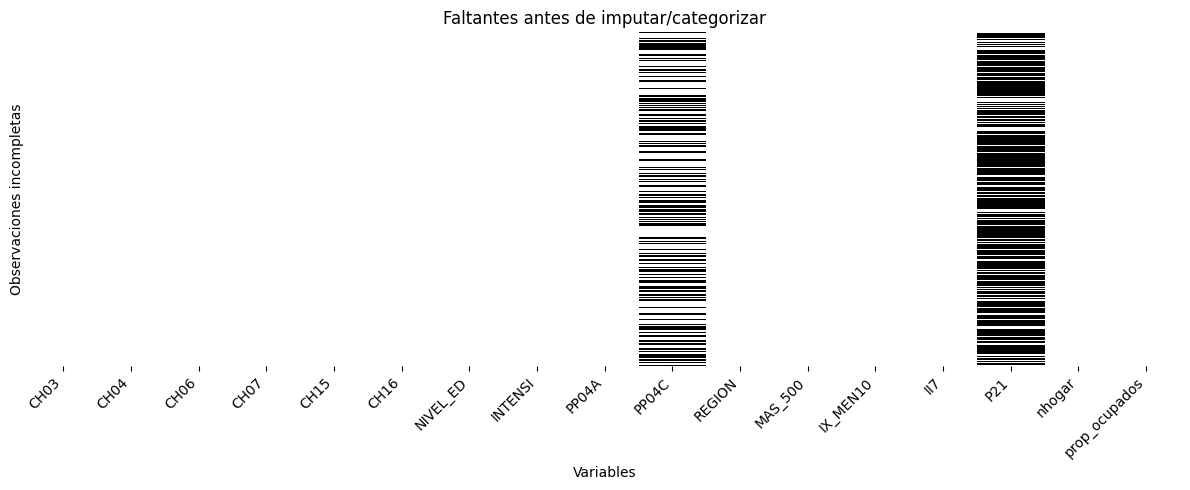

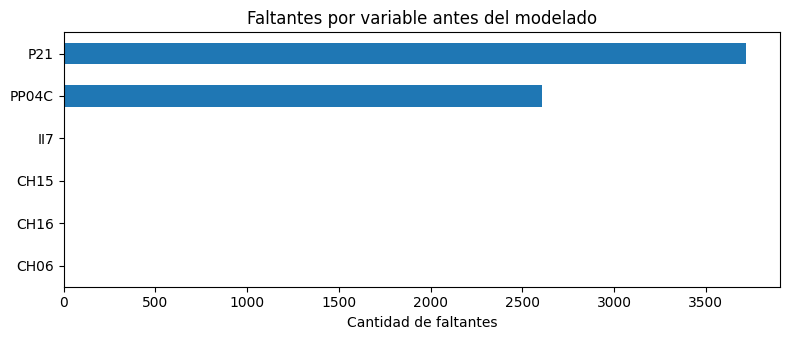

Base pre-modelado guardada: (19560, 24)
PP04C convertido a 'sin_dato' para modelar: 2607


In [10]:
# -----------------------------------------------------------------------------
# Diagnóstico de faltantes ANTES de imputar o convertir PP04C en 'sin_dato'.
# Esto describe la información realmente disponible en la base depurada.
# -----------------------------------------------------------------------------

X_diagnostico = pd.DataFrame(index=datos_indiv.index)
for v in ["CH03", "CH04", "CH06", "CH07", "CH15", "CH16", "NIVEL_ED",
          "INTENSI", "PP04A", "PP04C", "REGION", "MAS_500", "IX_MEN10", "II7"]:
    X_diagnostico[v] = datos_indiv[v]
# P21 se diagnostica después de recodificar -9 como NaN.
X_diagnostico["P21"] = datos_indiv["ingreso"]
# Variables construidas que ya existen y pueden reutilizarse.
X_diagnostico["nhogar"] = datos_indiv["nhogar"]
X_diagnostico["prop_ocupados"] = datos_indiv["prop_ocupados"]

tabla_faltantes = pd.DataFrame({
    "N_faltantes": X_diagnostico.isna().sum(),
    "Porcentaje": X_diagnostico.isna().mean() * 100
}).sort_values("N_faltantes", ascending=False)

display(tabla_faltantes.loc[tabla_faltantes.N_faltantes > 0].round(3))
print("Casos con algún valor NaN:", int(X_diagnostico.isna().any(axis=1).sum()))

# Controles de la auditoría (EPH 2026-T1, universo de 19.560 ocupados válidos).
esperados = {"P21": 3719, "PP04C": 2607, "II7": 5,
             "CH15": 2, "CH16": 1, "CH06": 1}
for variable, esperado in esperados.items():
    observado = int(X_diagnostico[variable].isna().sum())
    assert observado == esperado, f"{variable}: se esperaban {esperado} faltantes y hay {observado}."

# Superposición señalada por la auditoría: no sumar faltantes por variable como individuos.
solapamiento_p21_pp04c = int(
    X_diagnostico["P21"].isna().mul(X_diagnostico["PP04C"].isna()).sum()
)
print("Personas con P21 y PP04C faltantes simultáneamente:", solapamiento_p21_pp04c)

# Heatmap enfocado en observaciones incompletas.
X_faltantes = X_diagnostico.loc[X_diagnostico.isna().any(axis=1)]
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(X_faltantes.isna(), cmap="Greys", cbar=False,
            yticklabels=False, ax=ax)
ax.set(title="Faltantes antes de imputar/categorizar",
       xlabel="Variables", ylabel="Observaciones incompletas")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(join(b_path_figr, "heatmap_faltantes.png"), dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
tabla_faltantes.loc[tabla_faltantes.N_faltantes > 0, "N_faltantes"].sort_values().plot.barh(ax=ax)
ax.set(title="Faltantes por variable antes del modelado",
       xlabel="Cantidad de faltantes", ylabel="")
fig.tight_layout()
fig.savefig(join(b_path_figr, "faltantes_por_variable.png"), dpi=200, bbox_inches="tight")
plt.show()

tabla_faltantes.to_csv(
    join(b_path_tabl, "tabla_faltantes.csv"), encoding="utf-8-sig")

# -----------------------------------------------------------------------------
# Base depurada reutilizable: conserva identificadores, variables seleccionadas
# y NaN correctamente codificados. Todavía NO hay imputación ni dummies.
# -----------------------------------------------------------------------------
columnas_premodelo = (
    id_hogar + ["COMPONENTE", "informal"] +
    [v for v in variables_fuente if v not in ["IX_MEN10", "II7"]] +
    ["IX_MEN10", "II7", "ingreso", "log_ingreso", "ingreso_no_declara",
     "nhogar", "prop_ocupados"]
)
columnas_premodelo = list(dict.fromkeys(columnas_premodelo))
base_premodelo = datos_indiv[columnas_premodelo].copy()
base_premodelo.to_csv(
    join(b_path_data, "EPH_T126_premodelo.csv"),
    index=False, encoding="utf-8-sig")
print("Base pre-modelado guardada:", base_premodelo.shape)

# -----------------------------------------------------------------------------
# A partir de aquí sí se prepara la categoría explícita para el modelo.
# PP04C faltante se conserva como 'sin_dato'; PP04C=0 sigue siendo no aplicable.
# -----------------------------------------------------------------------------
datos_indiv["tamano_emp"] = datos_indiv["PP04C"].map(
    lambda x: "no_corresponde" if x == 0 else (
        f"tam_{int(x)}" if pd.notna(x) else "sin_dato")
)
print("PP04C convertido a 'sin_dato' para modelar:",
      int((datos_indiv["tamano_emp"] == "sin_dato").sum()))


In [11]:
# -----------------------------------------------------------------------------
# Preparación de la matriz predictiva SIN aprender transformaciones desde test.
# 1) split por individuo; 2) imputaciones aprendidas en train;
# 3) edad2 después de imputar CH06; 4) One-Hot fit sólo en train.
# -----------------------------------------------------------------------------

datos_modelo = datos_indiv.copy()
y_completo = datos_modelo["informal"].astype(int)

indice_train, indice_test = train_test_split(
    datos_modelo.index, train_size=.70, random_state=444)

train_modelo = datos_modelo.loc[indice_train].copy()
test_modelo = datos_modelo.loc[indice_test].copy()

# CH06: imputar exclusivamente con la mediana de train y luego construir edad2.
mediana_edad = train_modelo["CH06"].median()
train_modelo["CH06"] = train_modelo["CH06"].fillna(mediana_edad)
test_modelo["CH06"] = test_modelo["CH06"].fillna(mediana_edad)
train_modelo["edad2"] = train_modelo["CH06"] ** 2
test_modelo["edad2"] = test_modelo["CH06"] ** 2

# II7: el 0 ya fue convertido a NaN; la moda se aprende sólo en train.
moda_ii7 = train_modelo["II7"].mode(dropna=True).iloc[0]
train_modelo["II7"] = train_modelo["II7"].fillna(moda_ii7)
test_modelo["II7"] = test_modelo["II7"].fillna(moda_ii7)

variables_numericas = [
    "CH06", "edad2", "nhogar", "prop_ocupados", "log_ingreso",
    "ingreso_no_declara", "IX_MEN10"
]
variables_x = variables_numericas + variables_categoricas
variables_sin_ingreso = [v for v in variables_x
                         if v not in ["log_ingreso", "ingreso_no_declara", "IX_MEN10"]]

# Numéricas: mediana aprendida sólo en train (principalmente log_ingreso).
imputador_num = SimpleImputer(strategy="median", keep_empty_features=True)
num_train = pd.DataFrame(
    imputador_num.fit_transform(train_modelo[variables_numericas]),
    columns=variables_numericas, index=train_modelo.index)
num_test = pd.DataFrame(
    imputador_num.transform(test_modelo[variables_numericas]),
    columns=variables_numericas, index=test_modelo.index)

# Categóricas: los faltantes restantes son una categoría explícita.
cat_train = train_modelo[variables_categoricas].copy()
cat_test = test_modelo[variables_categoricas].copy()
for col in variables_categoricas:
    cat_train[col] = cat_train[col].fillna("sin_dato").astype(str)
    cat_test[col] = cat_test[col].fillna("sin_dato").astype(str)

# El codificador aprende categorías sólo en entrenamiento.
try:
    encoder = OneHotEncoder(drop="first", handle_unknown="ignore",
                            sparse_output=False, dtype=float)
except TypeError:  # compatibilidad con sklearn < 1.2
    encoder = OneHotEncoder(drop="first", handle_unknown="ignore",
                            sparse=False, dtype=float)

cat_train_arr = encoder.fit_transform(cat_train)
cat_test_arr = encoder.transform(cat_test)
cat_cols = encoder.get_feature_names_out(variables_categoricas)

cat_train_df = pd.DataFrame(cat_train_arr, columns=cat_cols, index=train_modelo.index)
cat_test_df = pd.DataFrame(cat_test_arr, columns=cat_cols, index=test_modelo.index)

X_train_base = pd.concat([num_train, cat_train_df], axis=1)
X_test_base = pd.concat([num_test, cat_test_df], axis=1)
y_train = y_completo.loc[indice_train].copy()
y_test = y_completo.loc[indice_test].copy()

assert len(X_train_base) == 13692 and len(X_test_base) == 5868
assert X_train_base.columns.equals(X_test_base.columns)
assert not X_train_base.isna().any().any() and not X_test_base.isna().any().any()
assert np.allclose(X_train_base["edad2"], X_train_base["CH06"] ** 2)
assert np.allclose(X_test_base["edad2"], X_test_base["CH06"] ** 2)

print("Mediana CH06 aprendida en train:", mediana_edad)
print("Moda II7 aprendida en train:", moda_ii7)
print("X_train antes de revisar rango:", X_train_base.shape)
print("X_test antes de revisar rango:", X_test_base.shape)
print("Número de predictores transformados:", X_train_base.shape[1])

# Matriz combinada únicamente para tablas descriptivas; el encoder ya fue fit sólo en train.
X_dummies = pd.concat([X_train_base, X_test_base]).sort_index()

resultados = []
for var in X_dummies.columns:
    formales = X_dummies.loc[y_completo == 0, var].dropna().astype(float)
    informales = X_dummies.loc[y_completo == 1, var].dropna().astype(float)
    t, p = stats.ttest_ind(informales, formales, equal_var=False)
    resultados.append({
        "Variable": var,
        "Formal": formales.mean(),
        "Informal": informales.mean(),
        "Diferencia": informales.mean() - formales.mean(),
        "t_stat": t,
        "p_valor": p
    })

tabla_medias = pd.DataFrame(resultados)
print("Ocupados:", len(datos_modelo), "| Columnas transformadas:", X_dummies.shape[1])
display(tabla_medias.loc[tabla_medias.Variable.isin(
    ["CH06", "edad2", "nhogar", "prop_ocupados", "log_ingreso", "ingreso_no_declara"]
)].round(3))
tabla_medias.to_csv(
    join(b_path_tabl, "tabla_diferencia_medias_completa.csv"),
    index=False, encoding="utf-8-sig")


Mediana CH06 aprendida en train: 41.0
Moda II7 aprendida en train: 1.0
X_train antes de revisar rango: (13692, 68)
X_test antes de revisar rango: (5868, 68)
Número de predictores transformados: 68
Ocupados: 19560 | Columnas transformadas: 68


C:\Users\JOEL\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Variable,Formal,Informal,Diferencia,t_stat,p_valor
0,CH06,43.483,39.393,-4.090,-21.487,0.000
1,edad2,2034.084,1753.447,-280.637,-16.696,0.000
2,nhogar,3.300,3.878,0.579,22.070,0.000
3,prop_ocupados,0.648,0.627,-0.021,-5.671,0.000
4,log_ingreso,13.748,12.599,-1.150,-38.133,0.000
5,ingreso_no_declara,0.198,0.180,-0.018,-3.117,0.002


## 3.3. Tablas LaTeX
Se exportan una tabla resumida y una completa para el informe.

In [12]:
etiquetas = {
    "CH06": "Edad (años)", "edad2":"Edad al cuadrado",
    "nhogar":"Integrantes del hogar",
    "prop_ocupados":"Proporción de ocupados del hogar",
    "log_ingreso":"Logaritmo del ingreso", "ingreso_no_declara":"Ingreso no declarado",
    "CH15_3":"Lugar de nacimiento (categoría 3)",
    "CH16_2":"Residencia anterior (categoría 2)",
    
    
    "CH04_2":"Mujer", "IX_MEN10":"Menores de 10 años en el hogar",
    "II7_2.0":"Tenencia de vivienda (categoría 2)",
    "II7_3.0":"Tenencia de vivienda (categoría 3)",
    "PP04A_2":"Establecimiento (categoría 2)", "NIVEL_ED_6":"Nivel educativo 6"
}
columnas={"Formal":"Formales","Informal":"Informales", "Diferencia":"Diferencia",
          "t_stat":"t", "p_valor":"p-valor"}
base_medias = tabla_medias.set_index("Variable")[list(columnas)].rename(columns=columnas)
principales=[v for v in etiquetas if v in base_medias.index]
tabla_principal=base_medias.loc[principales].rename(index=etiquetas)

def formato_es(v,dec=3):
    if pd.isna(v): return "--"
    s=f"{v:,.{dec}f}"
    return s.replace(",","#").replace(".",",").replace("#",".")
def formato_latex(t):
    r=t.copy().astype(object)
    for col in t.columns:
        if col=="p-valor":
            r[col]=t[col].map(lambda p: r"$<0{,}001$" if pd.notna(p) and p<.001 else formato_es(p))
        else:r[col]=t[col].map(lambda v: formato_es(v,2 if col=="t" else 3))
    r.index=r.index.map(lambda s: str(s).replace("_",r"\_"))
    return r

for tabla,nombre,etiqueta in [
    (tabla_principal,"tabla_diferencia_medias_resumen.tex","tab:dif_medias_resumen"),
    (base_medias,"tabla_diferencia_medias_completa.tex","tab:dif_medias_completa")]:
    formato_latex(tabla).to_latex(
        join(b_path_tabl, nombre),escape=False,
        caption="Diferencias de medias: trabajadores formales e informales",
        label=etiqueta,column_format="l"+"r"*len(tabla.columns))
print("Resumen:",len(tabla_principal),"filas | Tabla completa:",len(base_medias))
display(formato_latex(tabla_principal))

Resumen: 11 filas | Tabla completa: 68


,Formales,Informales,Diferencia,t,p-valor
Variable,,,,,
Edad (años),"43,483","39,393","-4,090","-21,49","$<0{,}001$"
Edad al cuadrado,"2.034,084","1.753,447","-280,637","-16,70","$<0{,}001$"
Integrantes del hogar,"3,300","3,878","0,579","22,07","$<0{,}001$"
Proporción de ocupados del hogar,"0,648","0,627","-0,021","-5,67","$<0{,}001$"
Logaritmo del ingreso,"13,748","12,599","-1,150","-38,13","$<0{,}001$"
Ingreso no declarado,"0,198","0,180","-0,018","-3,12","0,002"
Mujer,"0,448","0,461","0,013","1,85","0,065"
Menores de 10 años en el hogar,"0,352","0,454","0,102","9,86","$<0{,}001$"
Tenencia de vivienda (categoría 2),"0,044","0,071","0,027","7,87","$<0{,}001$"


# 4. Entrenamiento y prueba
La separación 70/30 con semilla 444 se realiza **antes** de aprender imputaciones o categorías. `CH06` se imputa con la mediana de train y luego se construye `edad2`; el One-Hot Encoder también se ajusta exclusivamente en train. Se conserva, además, una base pre-modelado independiente de la matriz final.


In [13]:
# Copias para la matriz final de modelado.
X_train = X_train_base.copy()
X_test = X_test_base.copy()

# Agregar constante para los modelos que la requieren explícitamente.
X_train.insert(0, "const", 1.0)
X_test.insert(0, "const", 1.0)
assert X_train.columns.equals(X_test.columns)

# Diagnóstico de rango: no eliminar variables por su significado económico.
# Se retiran sólo columnas linealmente redundantes en la muestra de entrenamiento.
columnas = X_train.columns.tolist()
matriz = X_train.to_numpy(dtype=float)
_, R, piv = qr(matriz, mode="economic", pivoting=True)
diag = np.abs(np.diag(R))
umbral = max(matriz.shape) * np.finfo(float).eps * diag.max()
rango_inicial = int((diag > umbral).sum())
print("Rango inicial:", rango_inicial, "de", len(columnas))

seleccionadas = ["const"]
eliminadas = []
for col in columnas:
    if col == "const":
        continue
    prueba = X_train[seleccionadas + [col]].to_numpy(dtype=float)
    if np.linalg.matrix_rank(prueba, tol=1e-9) > len(seleccionadas):
        seleccionadas.append(col)
    else:
        eliminadas.append(col)

X_train = X_train[seleccionadas].copy()
X_test = X_test[seleccionadas].copy()

print("Columnas redundantes eliminadas:", eliminadas)
print("Rango final:", np.linalg.matrix_rank(X_train.to_numpy(dtype=float)),
      "de", X_train.shape[1])
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Informalidad train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

assert X_train.columns.is_unique and X_test.columns.is_unique
assert not X_train.isna().any().any() and not X_test.isna().any().any()
assert len(X_train) == 13692 and len(X_test) == 5868

# Diagnóstico de hogares compartidos: no modifica el split solicitado por el TP.
hogares_train = set(map(tuple, datos_modelo.loc[y_train.index, id_hogar].drop_duplicates().to_numpy()))
hogares_test = set(map(tuple, datos_modelo.loc[y_test.index, id_hogar].drop_duplicates().to_numpy()))
hogares_compartidos = hogares_train.intersection(hogares_test)

llave_hogar = list(map(tuple, datos_modelo[id_hogar].to_numpy()))
en_hogar_compartido = pd.Series(
    [h in hogares_compartidos for h in llave_hogar],
    index=datos_modelo.index
)
print("Hogares presentes en train y test:", len(hogares_compartidos))
print("Trabajadores en hogares compartidos:", int(en_hogar_compartido.sum()))

# Base final de modelado: transformada, sin NaN y con partición explícita.
base_export = pd.concat([X_train, X_test]).sort_index()
base_export["informal"] = pd.concat([y_train, y_test]).sort_index()
base_export["conjunto"] = "train"
base_export.loc[X_test.index, "conjunto"] = "test"
base_export.to_csv(
    join(b_path_data, "EPH_T126_limpia.csv"),
    index=False, encoding="utf-8-sig")

print("Base de modelado guardada:", base_export.shape)
print("Base reutilizable guardada como EPH_T126_premodelo.csv")

# -----------------------------------------------------------------------------
# Pipeline preparado para KNN + Cross Validation.
# IMPORTANTE: usar datos sin imputar/dummificar para que cada fold aprenda
# imputación, edad², codificación y escalamiento solamente con su train fold.
# -----------------------------------------------------------------------------

class EPHFeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, categorical_cols=None):
        self.categorical_cols = categorical_cols

    def fit(self, X, y=None):
        X = X.copy()
        self.mediana_edad_ = pd.to_numeric(X["CH06"], errors="coerce").median()
        self.moda_ii7_ = X["II7"].mode(dropna=True).iloc[0]
        return self

    def transform(self, X):
        X = X.copy()
        X["CH06"] = pd.to_numeric(X["CH06"], errors="coerce").fillna(self.mediana_edad_)
        X["edad2"] = X["CH06"] ** 2
        X["II7"] = X["II7"].fillna(self.moda_ii7_)
        for col in self.categorical_cols:
            X[col] = X[col].fillna("sin_dato").astype(str)
        return X

numericas_knn = variables_numericas
categoricas_knn = variables_categoricas

pipeline_numerico_knn = Pipeline([
    ("imputador", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("escalador", StandardScaler())
])

try:
    onehot_knn = OneHotEncoder(drop="first", handle_unknown="ignore")
except TypeError:
    onehot_knn = OneHotEncoder(drop="first", handle_unknown="ignore")

preprocesador_knn = Pipeline([
    ("features", EPHFeatureBuilder(categorical_cols=categoricas_knn)),
    ("columnas", ColumnTransformer([
        ("num", pipeline_numerico_knn, numericas_knn),
        ("cat", onehot_knn, categoricas_knn)
    ], remainder="drop"))
])

pipeline_knn_cv = Pipeline([
    ("preprocesamiento", preprocesador_knn),
    ("modelo", KNeighborsClassifier())
])

variables_entrada_knn = [v for v in variables_numericas if v != "edad2"] + variables_categoricas
X_knn_raw = datos_modelo[variables_entrada_knn].copy()
y_knn = datos_modelo["informal"].astype(int)

print("Pipeline KNN-CV preparado. No se ajusta todavía en la Parte I.")
print("Para CV usar X_knn_raw e y_knn, no EPH_T126_limpia.csv ya transformada.")


Rango inicial: 69 de 69
Columnas redundantes eliminadas: []
Rango final: 69 de 69
X_train: (13692, 69) | X_test: (5868, 69)
Informalidad train/test: 0.456 0.4352
Hogares presentes en train y test: 2738
Trabajadores en hogares compartidos: 6679
Base de modelado guardada: (19560, 71)
Base reutilizable guardada como EPH_T126_premodelo.csv
Pipeline KNN-CV preparado. No se ajusta todavía en la Parte I.
Para CV usar X_knn_raw e y_knn, no EPH_T126_limpia.csv ya transformada.
